In [ ]:
# GPU

!nvidia-smi

In [2]:
# checking gpu is working or not
import torch
torch.cuda.is_available()

True

In [3]:
!pip install tensorflow opencv-python matplotlib scikit-learn seaborn

In [4]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

In [5]:
!unzip "Project Dataset" -d /content/dataset

Archive:  Project Dataset.zip
   creating: /content/dataset/Project Dataset/
  inflating: /content/dataset/Project Dataset/data.csv  
   creating: /content/dataset/Project Dataset/fake/
  inflating: /content/dataset/Project Dataset/fake/fake_1.jpg  
  inflating: /content/dataset/Project Dataset/fake/fake_10.jpg  
  inflating: /content/dataset/Project Dataset/fake/fake_100.jpg  
  inflating: /content/dataset/Project Dataset/fake/fake_101.jpg  
  inflating: /content/dataset/Project Dataset/fake/fake_102.jpg  
  inflating: /content/dataset/Project Dataset/fake/fake_103.jpg  
  inflating: /content/dataset/Project Dataset/fake/fake_104.jpg  
  inflating: /content/dataset/Project Dataset/fake/fake_105.jpg  
  inflating: /content/dataset/Project Dataset/fake/fake_106.jpg  
  inflating: /content/dataset/Project Dataset/fake/fake_107.jpg  
  inflating: /content/dataset/Project Dataset/fake/fake_108.jpg  
  inflating: /content/dataset/Project Dataset/fake/fake_109.jpg  
  inflating: /content/dat

In [7]:
!unzip -q /content/Project\ Dataset.zip -d /content/dataset

replace /content/dataset/Project Dataset/data.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [8]:
import os
import shutil
import random

base_path = '/content/dataset/Project Dataset'

classes = ['fake', 'real']

for cls in classes:
    os.makedirs(f'/content/dataset/train/{cls}', exist_ok=True)
    os.makedirs(f'/content/dataset/test/{cls}', exist_ok=True)

    images = os.listdir(f'{base_path}/{cls}')
    random.shuffle(images)

    split = int(0.8 * len(images))  # 80% train, 20% test

    train_imgs = images[:split]
    test_imgs = images[split:]

    for img in train_imgs:
        shutil.copy(f'{base_path}/{cls}/{img}', f'/content/dataset/train/{cls}/{img}')

    for img in test_imgs:
        shutil.copy(f'{base_path}/{cls}/{img}', f'/content/dataset/test/{cls}/{img}')

In [10]:
# Data Augmentation

from tensorflow.keras.preprocessing.image import ImageDataGenerator


train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

train_data = train_datagen.flow_from_directory(
    '/content/dataset/train',
    target_size=(224,224),
    batch_size=32,
    class_mode='binary'
)

test_data = test_datagen.flow_from_directory(
    '/content/dataset/test',
    target_size=(224,224),
    batch_size=32,
    class_mode='binary'
)

Found 1031 images belonging to 2 classes.
Found 258 images belonging to 2 classes.


In [12]:
#  Extracting Frame from videos

import cv2
import os

video_base = '/content/dataset/Project Dataset'
output_base = '/content/dataset/video_frames'

classes = {
    'videos_fake': 'fake',
    'videos_real': 'real'
}

for video_folder, label in classes.items():
    input_path = os.path.join(video_base, video_folder)
    output_path = os.path.join(output_base, label)

    os.makedirs(output_path, exist_ok=True)

    for video_file in os.listdir(input_path):
        video_path = os.path.join(input_path, video_file)
        cap = cv2.VideoCapture(video_path)

        frame_count = 0

        while True:
            ret, frame = cap.read()
            if not ret:
                break

            # Save every 10th frame (to reduce data size)
            if frame_count % 10 == 0:
                filename = f"{video_file}_frame{frame_count}.jpg"
                cv2.imwrite(os.path.join(output_path, filename), frame)

            frame_count += 1

        cap.release()

In [13]:
# Training frames from videos

import shutil
import random

base_path = '/content/dataset/video_frames'
classes = ['fake', 'real']

for cls in classes:
    os.makedirs(f'/content/dataset/video_train/{cls}', exist_ok=True)
    os.makedirs(f'/content/dataset/video_test/{cls}', exist_ok=True)

    images = os.listdir(f'{base_path}/{cls}')
    random.shuffle(images)

    split = int(0.8 * len(images))

    for img in images[:split]:
        shutil.copy(f'{base_path}/{cls}/{img}', f'/content/dataset/video_train/{cls}/{img}')

    for img in images[split:]:
        shutil.copy(f'{base_path}/{cls}/{img}', f'/content/dataset/video_test/{cls}/{img}')

In [14]:
# loading video dataset as images

video_train_data = train_datagen.flow_from_directory(
    '/content/dataset/video_train',
    target_size=(224,224),
    batch_size=32,
    class_mode='binary'
)

video_test_data = test_datagen.flow_from_directory(
    '/content/dataset/video_test',
    target_size=(224,224),
    batch_size=32,
    class_mode='binary'
)

Found 892 images belonging to 2 classes.
Found 224 images belonging to 2 classes.


In [15]:
# CNN Model (Image Detection)
# Transfer Learning (MobileNetV2)

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224,224,3))
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
# Training Model

history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=6
)

Epoch 1/6
33/33 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.8797 - loss: 0.2606 - val_accuracy: 0.9380 - val_loss: 0.1467
Epoch 2/6
33/33 ━━━━━━━━━━━━━━━━━━━━ 14s 439ms/step - accuracy: 0.9651 - loss: 0.1025 - val_accuracy: 0.9806 - val_loss: 0.0605
Epoch 3/6
33/33 ━━━━━━━━━━━━━━━━━━━━ 14s 435ms/step - accuracy: 0.9680 - loss: 0.0918 - val_accuracy: 0.9535 - val_loss: 0.1071
Epoch 4/6
33/33 ━━━━━━━━━━━━━━━━━━━━ 14s 411ms/step - accuracy: 0.9680 - loss: 0.0844 - val_accuracy: 0.9147 - val_loss: 0.2171
Epoch 5/6
33/33 ━━━━━━━━━━━━━━━━━━━━ 13s 407ms/step - accuracy: 0.9758 - loss: 0.0722 - val_accuracy: 0.9767 - val_loss: 0.0562
Epoch 6/6
33/33 ━━━━━━━━━━━━━━━━━━━━ 14s 411ms/step - accuracy: 0.9690 - loss: 0.0809 - val_accuracy: 0.9457 - val_loss: 0.1128


In [17]:
# Evaluating Model

preds = model.predict(test_data)
y_pred = (preds > 0.5).astype(int)

y_true = test_data.classes

print(classification_report(y_true, y_pred))

9/9 ━━━━━━━━━━━━━━━━━━━━ 11s 757ms/step
              precision    recall  f1-score   support

           0       0.56      0.61      0.59       140
           1       0.48      0.42      0.45       118

    accuracy                           0.53       258
   macro avg       0.52      0.52      0.52       258
weighted avg       0.52      0.53      0.52       258



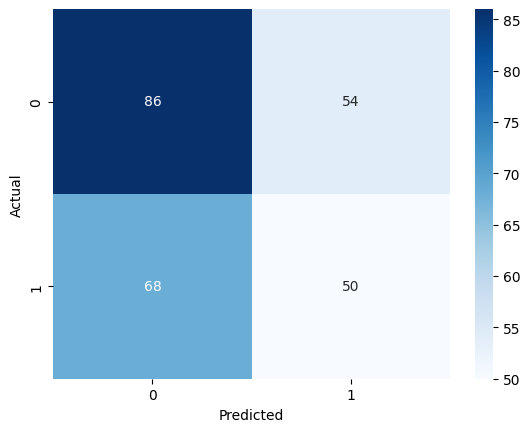

In [18]:
# Confusion Matrix

cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

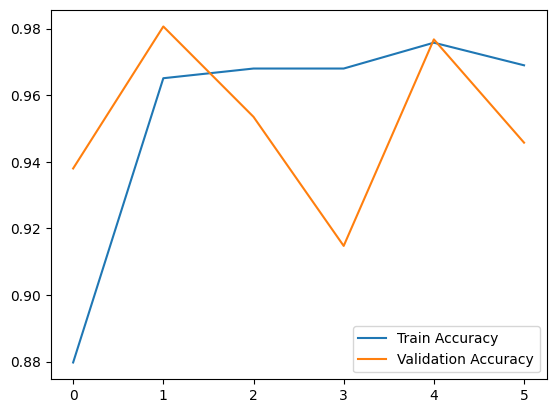

In [19]:
# Accuracy Graph

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.show()

In [20]:
# Heatmap (Grad-CAM for Fake Regions)

def get_gradcam_heatmap(model, img_array, last_conv_layer_name, pred_index=None):
    # Create a model that maps the input image to the last conv layer
    grad_model = Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Compute gradient
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    # Compute gradients
    grads = tape.gradient(class_channel, conv_outputs)

    # Mean of gradients
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiply each channel by importance
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalize
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    heatmap = heatmap.numpy()

    return heatmap

def overlay_heatmap(img_path, model, last_conv_layer_name='Conv_1'):
    img = image.load_img(img_path, target_size=(224,224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)/255.0

    heatmap = get_gradcam_heatmap(model, img_array, last_conv_layer_name)

    # Load original image
    img_orig = cv2.imread(img_path)
    img_orig = cv2.resize(img_orig, (224,224))

    heatmap = cv2.resize(heatmap, (img_orig.shape[1], img_orig.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    superimposed_img = cv2.addWeighted(img_orig, 0.6, heatmap, 0.4, 0)

    return superimposed_img

In [21]:
# Video Deepfake Detection (CNN + LSTM)

def extract_frames(video_path, max_frames=100):
    cap = cv2.VideoCapture(video_path)
    frames = []
    count = 0
    while cap.isOpened() and count < max_frames:
        ret, frame = cap.read()
        if not ret:
            break
        frame = cv2.resize(frame, (224,224))
        frames.append(frame)
        count += 1
    cap.release()
    return np.array(frames)

def predict_video(model_cnn, model_lstm, video_path):
    frames = extract_frames(video_path)
    frames_norm = frames/255.0
    cnn_features = model_cnn.predict(frames_norm)
    cnn_features = np.expand_dims(cnn_features, axis=0)  # LSTM expects batch

    pred = model_lstm.predict(cnn_features)
    fake_prob = float(pred[0][0])

    return fake_prob, frames

In [22]:
# CNN Feature Extraction

feature_extractor = models.Model(inputs=base_model.input,
                                 outputs=base_model.output)

def extract_features(frames):
    frames = frames / 255.0
    return feature_extractor.predict(frames)

In [23]:
# LSTM Model

lstm_model = models.Sequential([
    layers.TimeDistributed(layers.Flatten(), input_shape=(None,7,7,1280)),
    layers.LSTM(64),
    layers.Dense(1, activation='sigmoid')
])

lstm_model.compile(optimizer='adam',
                   loss='binary_crossentropy',
                   metrics=['accuracy'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/wrapper.py:27: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [28]:
# Fake Probability Over Time

def analyze_video(video_path):
    frames = extract_frames(video_path)
    features = extract_features(frames)

    features = np.expand_dims(features, axis=0)

    pred = lstm_model.predict(features)
    print("Video Fake Probability:", pred[0][0])

In [30]:
!pip install gradio tensorflow opencv-python-headless matplotlib -q
!apt-get install ffmpeg -y
!pip install opencv-python-headless gradio tensorflow

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ffmpeg is already the newest version (7:4.4.2-0ubuntu0.22.04.1).
0 upgraded, 0 newly installed, 0 to remove and 42 not upgraded.


In [32]:
import gradio as gr
import cv2
import numpy as np
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from PIL import Image
import tempfile
import os

# MODEL

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224,224,3))
x = GlobalAveragePooling2D()(base_model.output)
x = Dense(128, activation='relu')(x)
output = Dense(1, activation='sigmoid')(x)

cnn_model = Model(inputs=base_model.input, outputs=output)
cnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# IMAGE PREDICTION

def detect_image(img):
    if img is None:
        return "Please upload image", None

    img_arr = np.array(img)
    img_resized = cv2.resize(img_arr, (224, 224))
    img_norm = img_resized / 255.0
    img_input = np.expand_dims(img_norm, axis=0)

    pred = cnn_model.predict(img_input, verbose=0)[0][0]
    label = "Fake" if pred > 0.5 else "Real"

    # Simple heatmap overlay
    gray = cv2.cvtColor((img_input[0]*255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
    heatmap = cv2.applyColorMap(gray, cv2.COLORMAP_JET)
    overlay = cv2.addWeighted((img_input[0]*255).astype(np.uint8), 0.6, heatmap, 0.4, 0)

    return f"{label} ({pred:.2f})", overlay

# VIDEO PREDICTION

def predict_video(video_file):
    if video_file is None:
        return "Please upload video", None

    video_path = video_file.name
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        return "Error: Cannot open video", None

    predictions = []
    frame_count = 0
    temp_frames = []

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Process every 10th frame
        if frame_count % 10 == 0:
            frame_resized = cv2.resize(frame, (224, 224))
            frame_norm = frame_resized / 255.0
            frame_input = np.expand_dims(frame_norm, axis=0)

            pred = cnn_model.predict(frame_input, verbose=0)[0][0]
            predictions.append(pred)

            # Save frame for preview
            temp_frames.append(frame_resized)

        frame_count += 1

    cap.release()

    if len(predictions) == 0:
        return "Error: No frames extracted", None

    avg_pred = np.mean(predictions)
    label = "Fake Video" if avg_pred > 0.5 else "Real Video"

    # Save a short preview video
    preview_file = tempfile.NamedTemporaryFile(delete=False, suffix=".mp4")
    out = cv2.VideoWriter(preview_file.name, cv2.VideoWriter_fourcc(*'mp4v'), 10, (224,224))

    for f in temp_frames:
        out.write(f)
    out.release()

    return f"{label} ({avg_pred:.2f})", preview_file.name

#  GRADIO UI

with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("<h1 style='text-align:center; color:darkred'>Deepfake Image & Video Analyzer</h1>")

    # IMAGE TAB
    with gr.Tab("Image Detection"):
        with gr.Row():
            img_input = gr.Image(type="pil", label="Upload Image")
            img_output_text = gr.Textbox(label="Prediction")
            img_output_img = gr.Image(label="Heatmap")
        img_btn = gr.Button("Analyze Image")
        img_btn.click(fn=detect_image, inputs=img_input, outputs=[img_output_text, img_output_img])

    # VIDEO TAB
    with gr.Tab("Video Detection"):
        with gr.Row():
            vid_input = gr.File(label="Upload Video", file_types=[".mp4"])
            vid_output_text = gr.Textbox(label="Prediction")
            vid_output_video = gr.Video(label="Preview Video")
        vid_btn = gr.Button("Analyze Video")
        vid_btn.click(fn=predict_video, inputs=vid_input, outputs=[vid_output_text, vid_output_video])

#  LAUNCH

demo.launch(share=True)

/tmp/ipykernel_1525/549707012.py:97: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://098afcb6009bd6a135.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
